In [1]:
%pip install pandas numpy matplotlib seaborn scikit-learn

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

In [4]:
df = pd.read_csv("YouTube_Live_Merged.csv", low_memory=False)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (178628, 7)


,"""No.""","""Time""","""Source""","""Destination""","""Protocol""","""Length""","""Info"""
0,"""10.215.173.1""","""142.251.72.7""","""GQUIC""","""1278""","""Client Hello",PKN: 1,"CID: 4472406183105229454"""
1,"""10.215.173.1""","""142.251.72.7""","""GQUIC""","""936""","""Payload (Encrypted)",PKN: 2,"CID: 4472406183105229454"""
2,"""10.215.173.1""","""142.251.72.7""","""GQUIC""","""817""","""Payload (Encrypted)",PKN: 3,"CID: 4472406183105229454"""
3,"""10.215.173.1""","""142.251.72.7""","""GQUIC""","""931""","""Payload (Encrypted)",PKN: 4,"CID: 4472406183105229454"""
4,"""10.215.173.1""","""142.251.72.7""","""GQUIC""","""931""","""Payload (Encrypted)",PKN: 5,"CID: 4472406183105229454"""


In [5]:
print("Columns:")
print(df.columns.tolist())

print("\nData types and non-missing values:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nNumeric summary:")
display(df.describe(include="all").T)

Columns:
['"No."', '"Time"', '"Source"', '"Destination"', '"Protocol"', '"Length"', '"Info"']

Data types and non-missing values:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 178628 entries, 0 to 178627
Data columns (total 7 columns):
 #   Column         Non-Null Count   Dtype 
---  ------         --------------   ----- 
 0   "No."          178627 non-null  object
 1   "Time"         178627 non-null  object
 2   "Source"       178625 non-null  object
 3   "Destination"  178625 non-null  object
 4   "Protocol"     178625 non-null  object
 5   "Length"       178624 non-null  object
 6   "Info"         70721 non-null   object
dtypes: object(7)
memory usage: 9.5+ MB

Missing values:
"No."                 1
"Time"                1
"Source"              3
"Destination"         3
"Protocol"            3
"Length"              4
"Info"           107907
dtype: int64

Numeric summary:


,count,unique,top,freq
"""No.""",178627,37242,"""59.18.31.144""",40808
"""Time""",178627,63425,"""10.215.173.1""",107960
"""Source""",178625,30,"""GQUIC""",115221
"""Destination""",178625,849,"""1278""",99943
"""Protocol""",178625,13,"""Payload (Encrypted)",115130
"""Length""",178624,42318,"""1278""",42969
"""Info""",70721,1197,"""Protected Payload (KP0)""",47724


In [7]:
# Clean the column names by removing literal double quotes
df.columns = df.columns.str.replace('"', '')

required_columns = ["Time", "Protocol", "Length"]
missing_columns = [col for col in required_columns if col not in df.columns]

if missing_columns:
    raise ValueError(
        f"These required columns are missing: {missing_columns}. "
        f"Available columns are: {df.columns.tolist()}"
    )
else:
    print("All required columns are present and cleaned!")

All required columns are present and cleaned!


In [8]:
df = df.dropna(subset=["Protocol"]).copy()
df = df.drop_duplicates().copy()

df["Protocol"] = df["Protocol"].astype(str).str.strip()
df = df[df["Protocol"] != ""].copy()

print("Shape after cleaning:", df.shape)
print("\nProtocol counts:")
print(df["Protocol"].value_counts())

Shape after cleaning: (175376, 7)

Protocol counts:
Protocol
"Payload (Encrypted)    111881
"QUIC"                   47725
"UDP"                    14075
"TCP"                      901
"TLSv1.3"                  619
"Client Hello               73
"DNS"                       69
"Rejection                  18
"TLSv1"                      9
"R-GOOSE"                    2
"DCP-PFT"                    2
"Q                           1
"DCP-AF"                     1
Name: count, dtype: int64


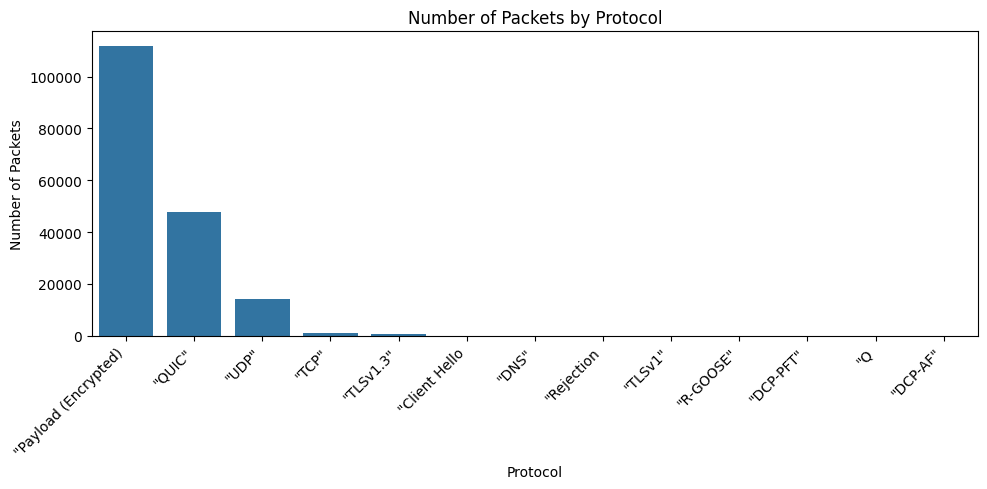

In [9]:
plt.figure(figsize=(10, 5))
sns.countplot(
    data=df,
    x="Protocol",
    order=df["Protocol"].value_counts().index
)
plt.xticks(rotation=45, ha="right")
plt.title("Number of Packets by Protocol")
plt.xlabel("Protocol")
plt.ylabel("Number of Packets")
plt.tight_layout()
plt.show()

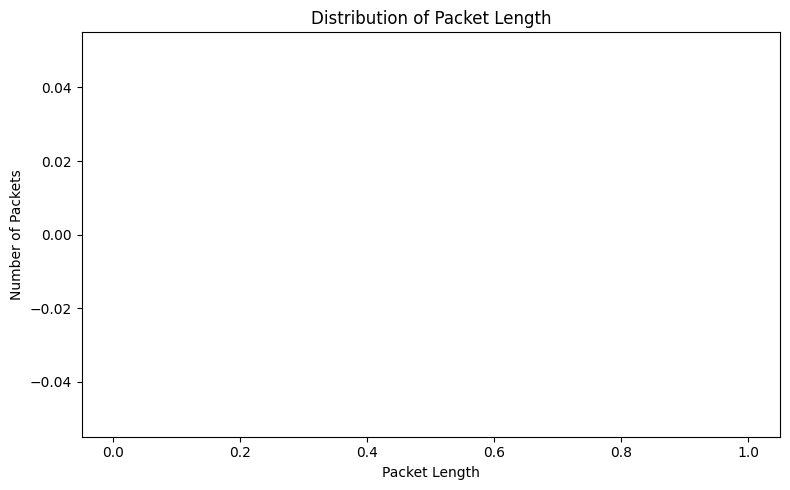

In [10]:
df["Length"] = pd.to_numeric(df["Length"], errors="coerce")

plt.figure(figsize=(8, 5))
plt.hist(df["Length"].dropna(), bins=40)
plt.title("Distribution of Packet Length")
plt.xlabel("Packet Length")
plt.ylabel("Number of Packets")
plt.tight_layout()
plt.show()

In [11]:
df["Time"] = pd.to_datetime(df["Time"], errors="coerce")

df["Hour"] = df["Time"].dt.hour
df["Minute"] = df["Time"].dt.minute
df["Second"] = df["Time"].dt.second

feature_columns = ["Length", "Hour", "Minute", "Second"]

for col in feature_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df[feature_columns] = df[feature_columns].fillna(0)

X = df[feature_columns]
y = df["Protocol"]

print("Features:")
display(X.head())

print("\nTarget:")
display(y.head())

print("\nNumber of examples:", len(df))

/tmp/ipykernel_1919/2328289123.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df["Time"] = pd.to_datetime(df["Time"], errors="coerce")


Features:


,Length,Hour,Minute,Second
0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0



Target:


,Protocol
0,"""Client Hello"
1,"""Payload (Encrypted)"
2,"""Payload (Encrypted)"
3,"""Payload (Encrypted)"
4,"""Payload (Encrypted)"



Number of examples: 175376


In [12]:
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

print("Protocol labels:", list(label_encoder.classes_))

class_counts = pd.Series(y_encoded).value_counts()
can_stratify = class_counts.min() >= 2

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.20,
    random_state=42,
    stratify=y_encoded if can_stratify else None
)

print("Training examples:", len(X_train))
print("Testing examples:", len(X_test))

Protocol labels: ['"Client Hello', '"DCP-AF"', '"DCP-PFT"', '"DNS"', '"Payload (Encrypted)', '"Q', '"QUIC"', '"R-GOOSE"', '"Rejection', '"TCP"', '"TLSv1"', '"TLSv1.3"', '"UDP"']
Training examples: 140300
Testing examples: 35076


In [13]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [14]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight="balanced"
    ),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=10,
        class_weight="balanced",
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )
}

results = []
trained_models = {}

for model_name, model in models.items():
    if model_name in ["Logistic Regression", "KNN"]:
        model.fit(X_train_scaled, y_train)
        predictions = model.predict(X_test_scaled)
    else:
        model.fit(X_train, y_train)
        predictions = model.predict(X_test)

    trained_models[model_name] = model

    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions)
    })

results_df = pd.DataFrame(results).sort_values(
    by="Accuracy",
    ascending=False
)

display(results_df)

,Model,Accuracy
1,KNN,0.633767
2,Decision Tree,0.276172
0,Logistic Regression,0.000371
3,Random Forest,0.000000


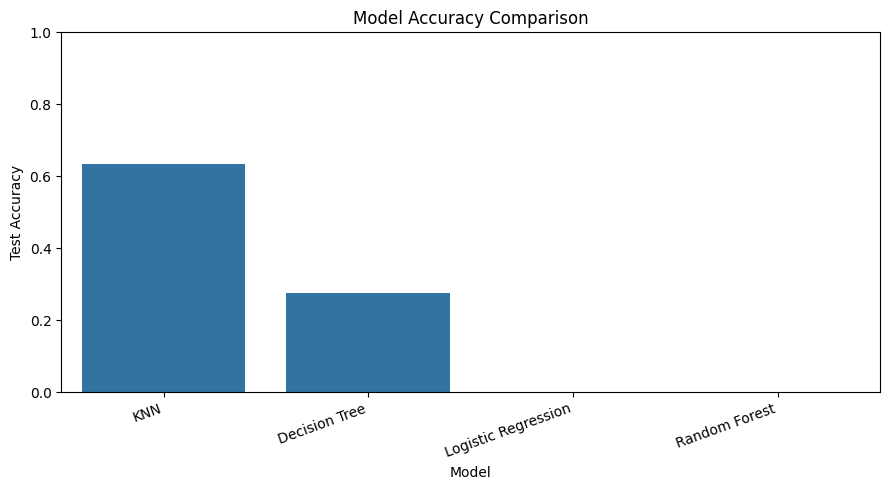

In [16]:
plt.figure(figsize=(9, 5))
sns.barplot(data=results_df, x="Model", y="Accuracy")
plt.ylim(0, 1)
plt.xticks(rotation=20, ha="right")
plt.title("Model Accuracy Comparison")
plt.ylabel("Test Accuracy")
plt.tight_layout()
plt.show()

In [17]:
best_model_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]

if best_model_name in ["Logistic Regression", "KNN"]:
    best_predictions = best_model.predict(X_test_scaled)
else:
    best_predictions = best_model.predict(X_test)

print("Best model by accuracy:", best_model_name)
print()
print(classification_report(
    y_test,
    best_predictions,
    labels=np.arange(len(label_encoder.classes_)),
    target_names=label_encoder.classes_,
    zero_division=0
))

Best model by accuracy: KNN

                      precision    recall  f1-score   support

       "Client Hello       0.00      0.00      0.00        13
            "DCP-AF"       0.00      0.00      0.00         0
           "DCP-PFT"       0.00      0.00      0.00         1
               "DNS"       0.00      0.00      0.00        12
"Payload (Encrypted)       0.63      1.00      0.78     22230
                  "Q       0.00      0.00      0.00         0
              "QUIC"       0.00      0.00      0.00      9687
           "R-GOOSE"       0.00      0.00      0.00         1
          "Rejection       0.00      0.00      0.00         6
               "TCP"       0.00      0.00      0.00       185
             "TLSv1"       0.00      0.00      0.00         2
           "TLSv1.3"       0.00      0.00      0.00       119
               "UDP"       0.00      0.00      0.00      2820

            accuracy                           0.63     35076
           macro avg       0.05      0.

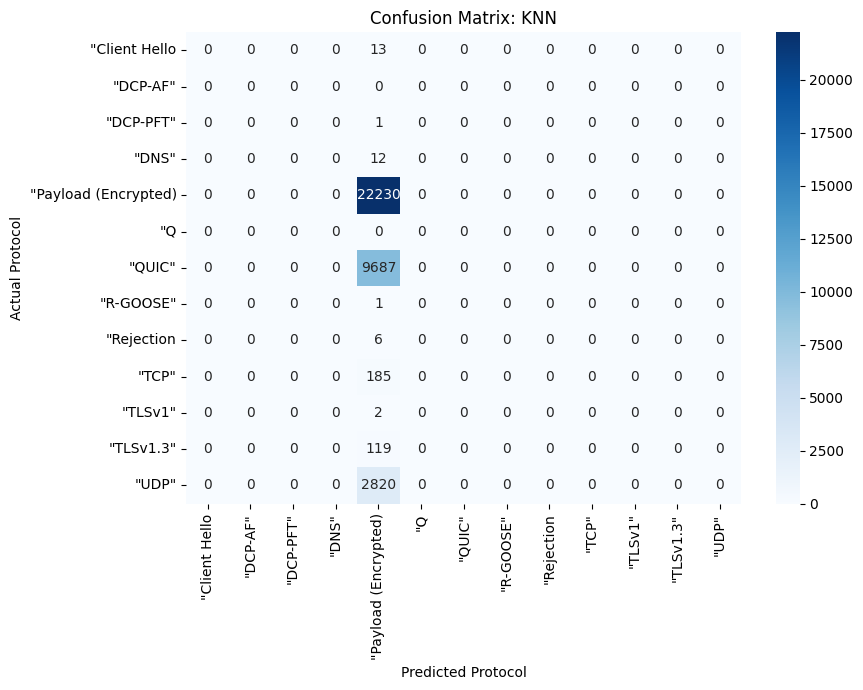

In [18]:
cm = confusion_matrix(
    y_test,
    best_predictions,
    labels=np.arange(len(label_encoder.classes_))
)

plt.figure(figsize=(9, 7))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)
plt.xlabel("Predicted Protocol")
plt.ylabel("Actual Protocol")
plt.title(f"Confusion Matrix: {best_model_name}")
plt.tight_layout()
plt.show()

In [19]:
new_packet = pd.DataFrame({
    "Length": [64],
    "Hour": [10],
    "Minute": [30],
    "Second": [15]
})

if best_model_name in ["Logistic Regression", "KNN"]:
    new_packet_input = scaler.transform(new_packet[feature_columns])
else:
    new_packet_input = new_packet[feature_columns]

predicted_number = best_model.predict(new_packet_input)
predicted_protocol = label_encoder.inverse_transform(predicted_number)

print("Sample packet:")
display(new_packet)

print("Predicted protocol:", predicted_protocol[0])

Sample packet:


,Length,Hour,Minute,Second
0,64,10,30,15


Predicted protocol: "Payload (Encrypted)


In [20]:
df = pd.read_csv("YouTube_Live_Merged.csv", low_memory=False)

# In the supplied file, these first four values are:
# source IP, destination IP, protocol, and packet length.
df.columns = [
    "Source_IP",
    "Destination_IP",
    "Protocol",
    "Length",
    "Info",
    "Packet_Number",
    "Connection_ID"
]

df["Protocol"] = df["Protocol"].astype(str).str.strip()
df["Length"] = pd.to_numeric(df["Length"], errors="coerce")

df = df.dropna(subset=["Protocol", "Length"])
df = df[df["Protocol"] != ""].drop_duplicates().copy()

print("Dataset shape:", df.shape)
print("\nActual protocol counts:")
print(df["Protocol"].value_counts())
display(df.head())

Dataset shape: (0, 7)

Actual protocol counts:
Series([], Name: count, dtype: int64)


,Source_IP,Destination_IP,Protocol,Length,Info,Packet_Number,Connection_ID


In [21]:
X = df[["Length"]]
y = df["Protocol"]

In [22]:
new_packet = pd.DataFrame({"Length": [64]})

In [23]:
MAX_ROWS = 100_000
MIN_PROTOCOL_COUNT = 5

if len(df) > MAX_ROWS:
    df = df.sample(n=MAX_ROWS, random_state=42).copy()

protocol_counts = df["Protocol"].value_counts()
valid_protocols = protocol_counts[protocol_counts >= MIN_PROTOCOL_COUNT].index

df = df[df["Protocol"].isin(valid_protocols)].copy()

X = df[["Length"]]
y = df["Protocol"]

print("Rows used:", len(df))
print("\nProtocol counts:")
print(y.value_counts())

Rows used: 0

Protocol counts:
Series([], Name: count, dtype: int64)


In [26]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

# 1. Reload and clean columns/values safely
df = pd.read_csv("YouTube_Live_Merged.csv", low_memory=False)
df.columns = df.columns.str.replace('"', '').str.strip()

# Strip quotes from string values
for col in df.select_dtypes(include='object').columns:
    df[col] = df[col].astype(str).str.replace('"', '').str.strip()

# Convert Length to numeric safely
df["Length"] = pd.to_numeric(df["Length"], errors="coerce")
df = df.dropna(subset=["Protocol", "Length"])
df = df[df["Protocol"] != ""].drop_duplicates().copy()

# Filter protocols with at least 5 samples
MIN_PROTOCOL_COUNT = 5
protocol_counts = df["Protocol"].value_counts()
valid_protocols = protocol_counts[protocol_counts >= MIN_PROTOCOL_COUNT].index
df = df[df["Protocol"].isin(valid_protocols)].copy()

X = df[["Length"]]
y = df["Protocol"]

# 2. Encode and Split
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.20,
    random_state=42,
    stratify=y_encoded
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Protocol labels:", list(label_encoder.classes_))

Training rows: 50718
Testing rows: 12680
Protocol labels: ['DNS', 'QUIC', 'TCP', 'TLSv1', 'TLSv1.3', 'UDP']


In [27]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [28]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight="balanced"
    ),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=10,
        class_weight="balanced",
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )
}

trained_models = {}
predictions_by_model = {}
results = []

for name, model in models.items():
    if name in ["Logistic Regression", "KNN"]:
        model.fit(X_train_scaled, y_train)
        predictions = model.predict(X_test_scaled)
    else:
        model.fit(X_train, y_train)
        predictions = model.predict(X_test)

    trained_models[name] = model
    predictions_by_model[name] = predictions

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions)
    })

results_df = pd.DataFrame(results).sort_values(
    by="Accuracy",
    ascending=False
)

display(results_df)

,Model,Accuracy
1,KNN,0.776814
3,Random Forest,0.433991
2,Decision Tree,0.423659
0,Logistic Regression,0.213644


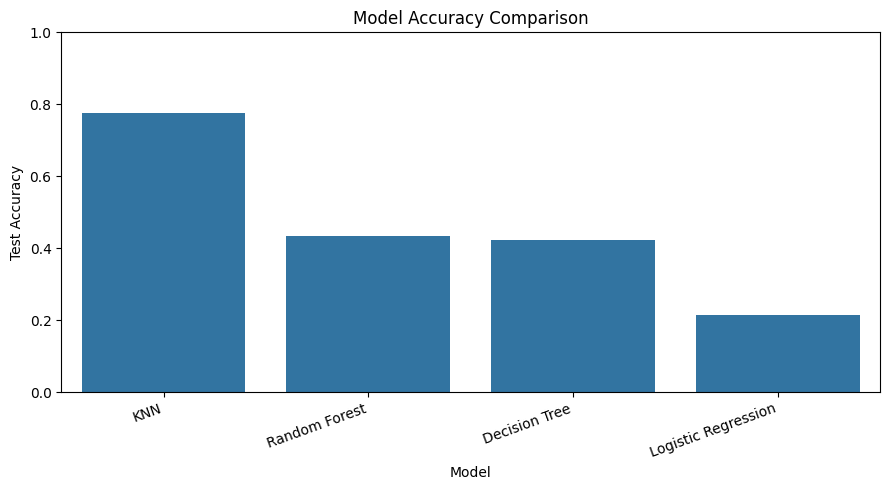

In [29]:
plt.figure(figsize=(9, 5))
sns.barplot(data=results_df, x="Model", y="Accuracy")
plt.ylim(0, 1)
plt.xticks(rotation=20, ha="right")
plt.title("Model Accuracy Comparison")
plt.ylabel("Test Accuracy")
plt.tight_layout()
plt.show()

In [30]:
from sklearn.metrics import classification_report

best_model_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]
best_predictions = predictions_by_model[best_model_name]

print("Best model by accuracy:", best_model_name)
print()

print(classification_report(
    y_test,
    best_predictions,
    labels=np.arange(len(label_encoder.classes_)),
    target_names=label_encoder.classes_,
    zero_division=0
))

Best model by accuracy: KNN

              precision    recall  f1-score   support

         DNS       0.67      0.14      0.24        14
        QUIC       0.78      0.99      0.87      9545
         TCP       1.00      0.93      0.97       180
       TLSv1       0.00      0.00      0.00         2
     TLSv1.3       0.85      0.81      0.83       124
         UDP       0.62      0.04      0.08      2815

    accuracy                           0.78     12680
   macro avg       0.65      0.49      0.50     12680
weighted avg       0.75      0.78      0.69     12680



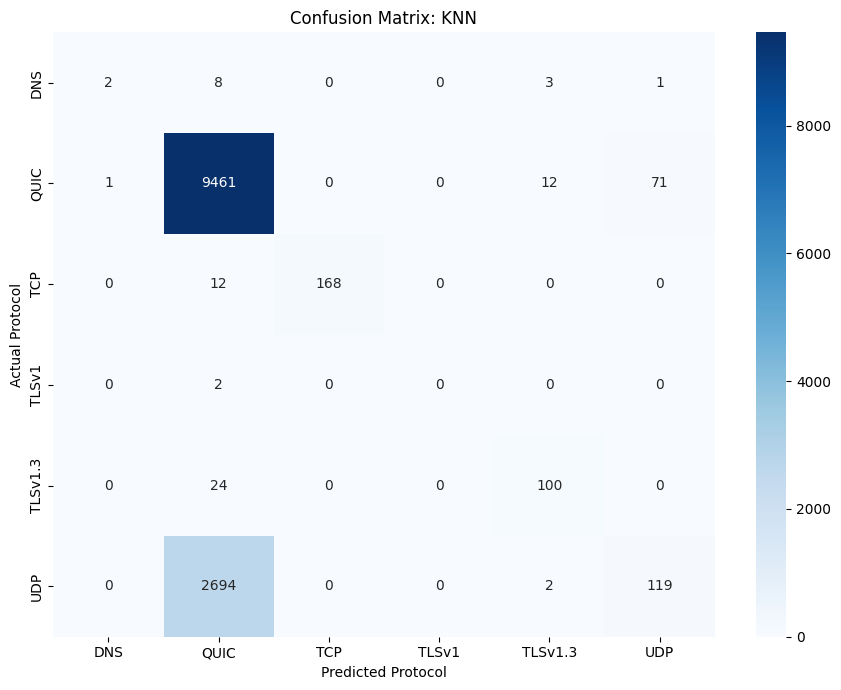

In [31]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    y_test,
    best_predictions,
    labels=np.arange(len(label_encoder.classes_))
)

plt.figure(figsize=(9, 7))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)
plt.xlabel("Predicted Protocol")
plt.ylabel("Actual Protocol")
plt.title(f"Confusion Matrix: {best_model_name}")
plt.tight_layout()
plt.show()

In [32]:
new_packet = pd.DataFrame({"Length": [64]})

if best_model_name in ["Logistic Regression", "KNN"]:
    new_packet_scaled = scaler.transform(new_packet)
    predicted_number = best_model.predict(new_packet_scaled)
else:
    predicted_number = best_model.predict(new_packet)

predicted_protocol = label_encoder.inverse_transform(predicted_number)

print("Sample packet length:", new_packet.loc[0, "Length"])
print("Predicted protocol:", predicted_protocol[0])

Sample packet length: 64
Predicted protocol: UDP


Feature importance:


,Feature,Importance
0,Length,1.0


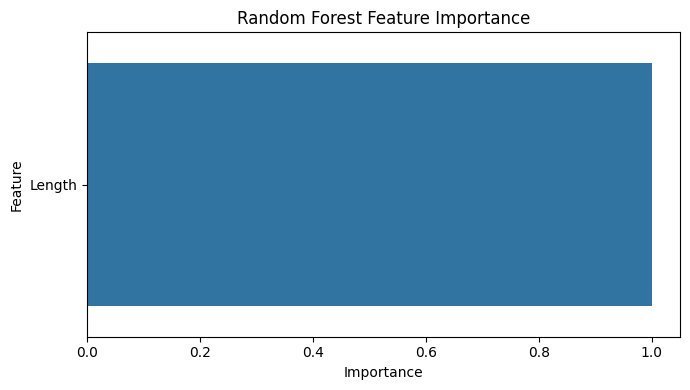

In [33]:
random_forest_model = trained_models["Random Forest"]

feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": random_forest_model.feature_importances_
}).sort_values(by="Importance", ascending=False)

print("Feature importance:")
display(feature_importance)

plt.figure(figsize=(7, 4))
sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature"
)
plt.title("Random Forest Feature Importance")
plt.tight_layout()
plt.show()